# A Simplified River Flood Model: Overflow Above a Dyke

__M. Lamboni__, Université Paris Descartes, 45 rue des saints Pères, F-75006, France, and IMT, F-31062, France

__B. Iooss__, EDF R&D, 6 quai Watier, F-78401, France

__A.-L. Popelin__, EDF R&D, 6 quai Watier, F-78401, France

__F. Gamboa__, IMT, F-31062, France

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The model and the input distributions are those of Lamboni et al. [[1]](https://doi.org/10.1016/j.matcom.2013.02.002), Section 4.3. The text read for this notebook is the authors' manuscript (arXiv:1202.0943v2, 2 July 2012), not the published version; page and table numbers below refer to that manuscript. The notebook runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes about ten seconds.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import flood_model as fm

SEED = 2013                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
names = list(fm.NAMES)
labels = [r'$Q$', r'$K_s$', r'$Z_v$', r'$Z_m$', r'$H_d$', r'$C_b$', r'$L$', r'$B$']

### Summary

Lamboni et al. [[1]](https://doi.org/10.1016/j.matcom.2013.02.002) test derivative-based global sensitivity measures (DGSM) on a closed-form simplification of the 1-D Saint-Venant equations that gives the maximal annual overflow $S$ of a river above a dyke as a function of eight independent inputs with truncated Gumbel, truncated normal, triangular and uniform distributions. We sample those distributions, compute exact gradients of $S$ at 10 000 points, and find a one-dimensional active subspace ($\lambda_1/\lambda_2 = 47.0$, 97.0 % of the trace) led by the dyke height, the flowrate, the downstream level and the Strickler coefficient, on which a line in the active variable has leave-one-out $R^2 = 0.9783$. Exact quadrature reproduces the paper's Sobol' indices to within 0.008, but shows that every DGSM $\nu_j$ in its Table 5 is 0.838–0.839 times the exact value, which is why the table gives $\nu = 0.8389$ instead of 1 for $H_d$ and $C_b$.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. The diagonal of $\mathbf C$ holds the derivative-based global sensitivity measures (DGSM) of the normalized inputs, which is how this notebook connects to the paper. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

Lamboni et al. [[1]](https://doi.org/10.1016/j.matcom.2013.02.002) (Sec. 4.3, Eq. (4.20), p. 14) use a crude simplification of the 1-D Saint-Venant equations, for uniform and constant flow in a wide rectangular channel with the Strickler friction law, taken from Iooss [2]. The maximal annual height of the river and the maximal annual overflow above the dyke are

$$
H = \left(\frac{Q}{B\,K_s\sqrt{(Z_m - Z_v)/L}}\right)^{0.6},\qquad S = Z_v + H - H_d - C_b \quad\text{(m)},
$$

where $Q$ is the maximal annual flowrate, $K_s$ the Strickler coefficient, $Z_v$ and $Z_m$ the downstream and upstream river levels, $L$ and $B$ the length and width of the river stretch, $H_d$ the dyke height (a design parameter) and $C_b$ the bank level. Flooding occurs when $S > 0$.

**Quantity of interest.** The overflow $S$ in metres. It is smooth on the whole input domain, and its gradient is exact and cheap:
$\partial S/\partial Q = 0.6H/Q$, $\partial S/\partial K_s = -0.6H/K_s$, $\partial S/\partial Z_v = 1 + 0.3H/(Z_m-Z_v)$, $\partial S/\partial Z_m = -0.3H/(Z_m-Z_v)$, $\partial S/\partial H_d = \partial S/\partial C_b = -1$, $\partial S/\partial L = 0.3H/L$, $\partial S/\partial B = -0.6H/B$.
Because $S$ depends on $Z_v$, $H_d$ and $C_b$ only through $Z_v - H_d - C_b$ and $Z_m - Z_v$, it is a function of six combinations of the eight inputs, so $\mathbf C$ has two exactly zero eigenvalues.

**The second output and its kink.** The paper also uses a cost in million euros (Eq. (4.21)),
$C_p = \mathbb 1_{S>0} + \left[0.2 + 0.8\left(1 - e^{-1000/S^4}\right)\right]\mathbb 1_{S\le 0} + \tfrac{1}{20}\left(H_d\mathbb 1_{H_d>8} + 8\,\mathbb 1_{H_d\le 8}\right)$.
The first two terms join continuously (and smoothly) at $S = 0$, but that branch is never reached: on the support of the inputs $S \le -3.66$ m (the code cell below computes the bound), so no sample floods. The investment term $\max(H_d, 8)/20$ has a kink at $H_d = 8$ m, the middle of the dyke-height range, where $\partial C_p/\partial H_d$ jumps by $1/20$. We use the smooth $S$ as the quantity of interest and look at $C_p$ only briefly at the end.

**Inputs.** Independent, with the distributions of Table 4 (p. 14). We read $\mathcal N(30, 8)$ as mean 30 and *standard deviation* 8: the paper's own Morris test (Table 3, p. 12) gives the constant $C = 0.01$ to $\mathcal N(0.5, 0.1)$, which is $\sigma^2$ only if the second parameter is $\sigma$, and Iooss [2] gives this input a standard deviation. $\mathcal G(1013, 558)$ is the Gumbel (maximum) law with location 1013 and scale 558 (Table 1, p. 8), and $\mathcal T(a, c, b)$ is triangular with minimum $a$, mode $c$, maximum $b$. Table 4 gives $K_s$ no unit; it is m$^{1/3}$ s$^{-1}$. The table below is built from `flood_model.py`; the means and standard deviations are exact (quadrature).

In [2]:
mean, sd = fm.mean_and_sd()
print(f"{'input':5s} {'units':10s} {'distribution (Table 4)':46s} {'mean':>10s} {'std':>9s}  description")
for j, n in enumerate(names):
    print(f'{n:5s} {fm.UNITS[j]:10s} {fm.DISTRIBUTIONS[j]:46s} {mean[j]:10.4f} {sd[j]:9.5f}  {fm.DESCRIPTIONS[j]}')
x_worst = np.array([fm.Q_HI, fm.KS_LO, 51.0, 54.0, fm.HD_LO, 55.0, 5010.0, 295.0])
print(f'\nlargest overflow on the support (Q = 3000, Ks = 15, Zv = 51, Zm = 54, Hd = 7, Cb = 55, '
      f'L = 5010, B = 295): S = {fm.overflow(x_worst):.3f} m')

input units      distribution (Table 4)                               mean       std  description
Q     m^3/s      truncated Gumbel G(1013, 558) on [500, 3000]    1356.8782 561.14675  maximal annual flowrate
Ks    m^(1/3)/s  truncated normal N(30, 8) on [15, +inf)           30.5675   7.42730  Strickler coefficient
Zv    m          triangular T(49, 50, 51)                          50.0000   0.40825  river downstream level
Zm    m          triangular T(54, 55, 56)                          55.0000   0.40825  river upstream level
Hd    m          uniform U[7, 9]                                    8.0000   0.57735  dyke height
Cb    m          triangular T(55, 55.5, 56)                        55.5000   0.20412  bank level
L     m          triangular T(4990, 5000, 5010)                  5000.0000   4.08248  length of the river stretch
B     m          triangular T(295, 300, 305)                      300.0000   2.04124  river width

largest overflow on the support (Q = 3000, Ks = 15, Zv = 51,

### Load data

`generate_data.py` drew $M = 10\,000$ independent samples of the inputs by the inverse CDF (seed 2013) and wrote the physical inputs, $S$ and $C_p$, and their exact gradients with respect to the physical inputs (see `DATA.md`). The paper's DGSM estimates also used $10^4$ points (a Sobol' sequence, p. 15).

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')                  # (M, 8) physical inputs
F = np.loadtxt('outputs.csv', delimiter=',')                 # (M, 2): S in m, Cp in million euros
G_all = np.loadtxt('gradients.csv', delimiter=',')           # (M, 16): dS/dx, dCp/dx (physical)
f, cp = F[:, 0], F[:, 1]
G, Gcp = G_all[:, :8], G_all[:, 8:]
print(f'inputs {X.shape}, outputs {F.shape}, gradients {G_all.shape}')

inputs (10000, 8), outputs (10000, 2), gradients (10000, 16)


We check the files against the model, the exact gradients against central finite differences (step $10^{-6}$ standard deviations), and the sample mean and variance of $S$ against their exact values, computed by quadrature in `flood_model.exact_moments`.

In [4]:
h = 1e-6 * sd
G_fd = np.column_stack([(fm.overflow(X + h[j] * e) - fm.overflow(X - h[j] * e)) / (2 * h[j])
                        for j, e in enumerate(np.eye(8))])
ex = fm.exact_moments()
print(f'max |model - outputs.csv| = {np.max(np.abs(fm.overflow(X) - f)):.1e} m; '
      f'gradients vs central differences: max relative error '
      f'{np.max(np.linalg.norm(G_fd - G, axis=1) / np.linalg.norm(G, axis=1)):.1e}')
print(f'S: sample mean {f.mean():.4f} m (exact {ex["mean"]:.4f}), sample variance {f.var(ddof=1):.4f} m^2 '
      f'(exact {ex["var"]:.4f}); range [{f.min():.3f}, {f.max():.3f}] m')

max |model - outputs.csv| = 1.4e-14 m; gradients vs central differences: max relative error 1.4e-08
S: sample mean -10.9342 m (exact -10.9445), sample variance 1.2087 m^2 (exact 1.1745); range [-14.309, -5.972] m


### Estimate the subspace

The model is closed-form, so we use exact gradients and the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates. The samples come from the paper's distributions; the input space only says how each input is normalized, and the library applies that map once to the physical inputs and gradients we pass:

- $H_d$ is uniform, so it gets `ac.Uniform(7, 9)`, which maps $[7, 9]$ to $[-1, 1]$ (scale 1 m, which is $\sqrt3$ standard deviations).
- The seven other inputs are not uniform or Gaussian, so they get `ac.Gaussian` blocks with each marginal's exact mean and variance (the table above). These blocks are used only for their affine map $x^{\mathrm{norm}}_j = (x_j - \mu_j)/\sigma_j$, which centres each input and scales it by one standard deviation; they do not change the samples, which are triangular, truncated Gumbel and truncated normal. This choice also keeps the unbounded $K_s$ on the same footing as the bounded inputs.

So the normalized gradient is $\sigma_j\,\partial S/\partial x_j$ for seven inputs and $1\,\mathrm{m}\cdot\partial S/\partial H_d$ for $H_d$, and the diagonal of $\mathbf C$ is $\sigma_j^2\nu_j$ (with 1 m$^2$ in place of $\sigma_j^2$ for $H_d$), where $\nu_j = \mathbb E[(\partial S/\partial x_j)^2]$ is the paper's DGSM. We use 500 bootstrap replicates and the library's eigenvalue-gap rule. A second analysis, in transformed variables, follows the results.

In [5]:
space = ac.Product([ac.Gaussian(mean[:4], sd[:4]**2, names=names[:4]),
                    ac.Uniform([fm.HD_LO], [fm.HD_HI], names=['Hd']),
                    ac.Gaussian(mean[5:], sd[5:]**2, names=names[5:])])
sub = ac.active_subspace(space=space, X=X, f=f, grads=G, estimator='as', nboot=500, rng=SEED)
sub = ac.orient(sub, by='mean_gradient', grads=G)   # sign: S increases along w1
lam, W = sub.eigenvalues, sub.eigenvectors
ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
lo, hi = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
print('eigenvalues:', np.array2string(lam, precision=4))
print(f'n = {sub.n} (eigenvalue-gap rule picks {k_hat}); lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, '
      f'lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}, lambda_3/lambda_4 = {lam[2] / lam[3]:.1f}')
print(f'95% bootstrap range: lambda_1 [{lo[0]:.4f}, {hi[0]:.4f}], lambda_2 [{lo[1]:.4f}, {hi[1]:.4f}], '
      f'lambda_3 [{lo[2]:.4f}, {hi[2]:.4f}]')
print(f'share of trace: lambda_1 {lam[0] / lam.sum():.4f}, lambda_1 + lambda_2 {lam[:2].sum() / lam.sum():.4f}')

eigenvalues: [1.9150e+00 4.0753e-02 1.8615e-02 2.1117e-04 2.2850e-07 1.8724e-11
 1.8518e-33 8.7198e-34]
n = 1 (eigenvalue-gap rule picks 1); lambda_1/lambda_2 = 47.0, lambda_2/lambda_3 = 2.19, lambda_3/lambda_4 = 88.2
95% bootstrap range: lambda_1 [1.9082, 1.9206], lambda_2 [0.0388, 0.0427], lambda_3 [0.0181, 0.0191]
share of trace: lambda_1 0.9698, lambda_1 + lambda_2 0.9905


### Results

**Eigenvalues.** The figure shows the eigenvalues with a 95 % bootstrap band.

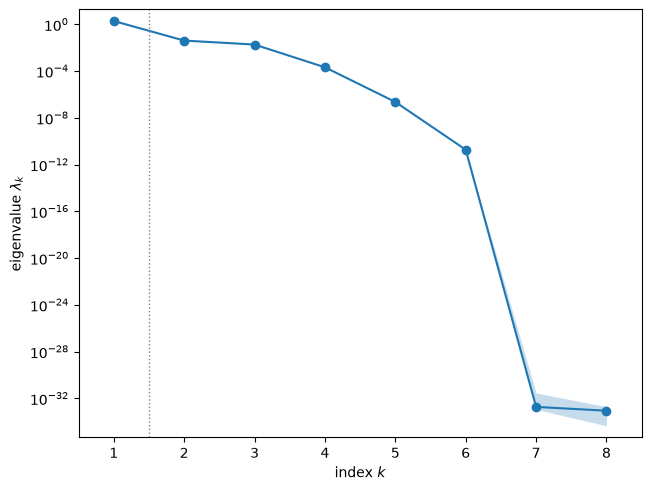

In [6]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
fig

The first eigenvalue, $\lambda_1 = 1.915$ (95 % bootstrap range 1.908–1.921), is 47.0 times $\lambda_2 = 0.0408$ and holds 97.0 % of the trace; $\lambda_2/\lambda_3 = 2.19$, $\lambda_3/\lambda_4 = 88.2$, and the gap rule picks $n = 1$. $\lambda_5 = 2.3\times10^{-7}$ and $\lambda_6 = 1.9\times10^{-11}$ belong to the nearly irrelevant $B$ and $L$ (their eigenvectors are 0.998 on $B$ and on $L$), and $\lambda_7, \lambda_8 \approx 10^{-33}$ are rounding errors on the two exactly null directions described in the model section.

bootstrap mean subspace distance, k = 1..7: [1.675e-03 8.728e-03 1.363e-03 3.520e-04 9.202e-05 2.356e-13 7.837e-01]


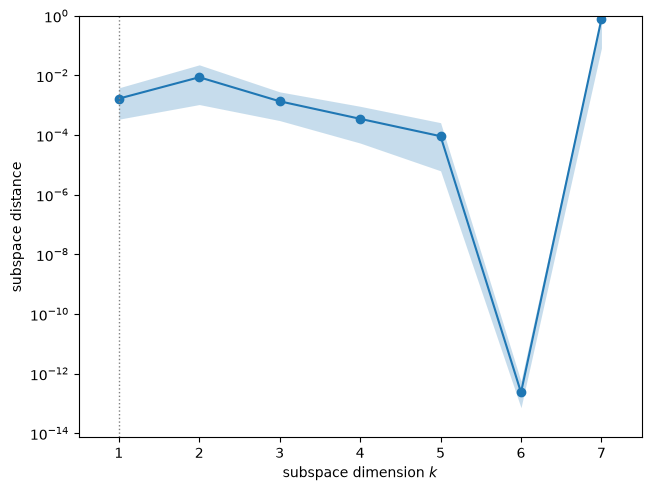

In [7]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..7:',
      np.array2string(sub.bootstrap_distances.mean(axis=0), precision=3))
fig

The bootstrap mean subspace distance for $n = 1$ is $1.7\times10^{-3}$: with 10 000 exact gradients, $\mathbf w_1$ is well determined. For $k = 2$ it is $8.7\times10^{-3}$, since $\lambda_2$ and $\lambda_3$ are only a factor 2.19 apart. For $k = 6$ it is of order $10^{-13}$, because that subspace is the complement of the two exact null directions; for $k = 7$ it is large (0.78; the value changes from machine to machine), because the subspace splits the two zero eigenvalues and is arbitrary.

w1: Q +0.4959, Ks -0.3093, Zv +0.3406, Zm -0.0466, Hd -0.7201, Cb -0.1470, L +0.0005, B -0.0076
w2: Q +0.1241, Ks +0.9433, Zv +0.0481, Zm +0.0701, Hd -0.2896, Cb -0.0591, L -0.0007, B +0.0112
lambda_7, lambda_8 = 1.9e-33, 8.7e-34; largest |C n| over the two exact null directions: 1.9e-15


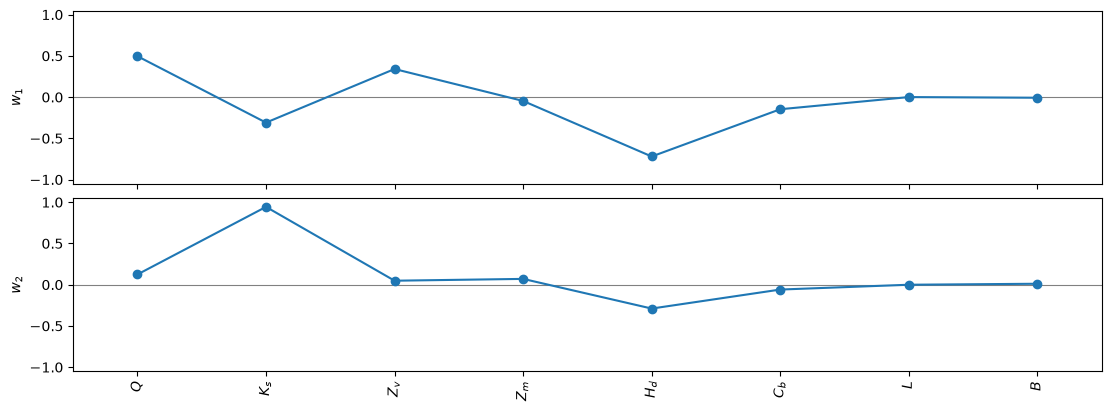

In [8]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, figsize=(11, 4))
plt.close(fig)
w1, w2 = W[:, 0], W[:, 1]
print('w1:', ', '.join(f'{n} {v:+.4f}' for n, v in zip(names, w1)))
print('w2:', ', '.join(f'{n} {v:+.4f}' for n, v in zip(names, w2)))
null = np.zeros((2, 8))
null[0, [4, 5]] = [sd[5], -1.0]                       # Hd - Cb direction (normalized coordinates)
null[1, [2, 3, 4]] = [1 / sd[2], 1 / sd[3], 1.0]      # Zv + Zm + Hd direction
null /= np.linalg.norm(null, axis=1, keepdims=True)
print(f'lambda_7, lambda_8 = {lam[6]:.1e}, {lam[7]:.1e}; largest |C n| over the two exact null directions: '
      f'{np.max(np.abs(null @ (space.grads_to_normalized(G).T @ space.grads_to_normalized(G) / len(G)))):.1e}')
fig

$\mathbf w_1$ weights $H_d$ by $-0.720$, $Q$ by $+0.496$, $Z_v$ by $+0.341$, $K_s$ by $-0.309$ and $C_b$ by $-0.147$; $Z_m$ ($-0.047$), $B$ ($-0.008$) and $L$ ($0.0005$) hardly matter. The signs are physical: the overflow grows with the flowrate and the downstream level, and falls with the dyke height, the bank level and the Strickler coefficient (a smoother channel carries the same flow lower). $H_d$ leads partly because of the normalization: its scale in `ac.Uniform` is its half-range, 1 m, which is $\sqrt3$ standard deviations, so its weight is larger than it would be with the standard-deviation scaling of the other inputs (see the comparison section). $\mathbf w_2$ is mostly $K_s$ ($+0.943$, with $-0.290$ on $H_d$ and $+0.124$ on $Q$) and carries the curvature of $H \propto K_s^{-0.6}$. The two null directions (an increase of $H_d$ with an equal decrease of $C_b$, and an equal increase of $Z_v$, $Z_m$ and $H_d$, which leave $Z_v - H_d - C_b$ and $Z_m - Z_v$ unchanged) are annihilated by $\hat{\mathbf C}$ to rounding error (below $10^{-13}$).

active variable y1 = w1^T x: range [-2.67, 3.10]; corr(S, y1) = 0.9891


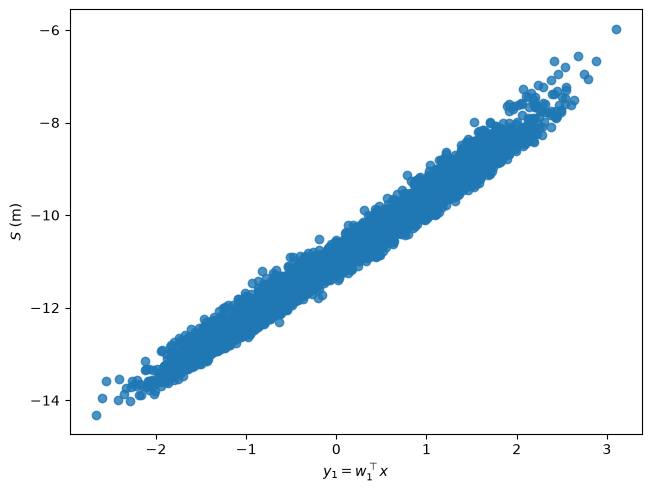

In [9]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label=r'$S$ (m)')
plt.close(fig)
y = space.to_normalized(X) @ W[:, :2]
print(f'active variable y1 = w1^T x: range [{y[:, 0].min():.2f}, {y[:, 0].max():.2f}]; '
      f'corr(S, y1) = {np.corrcoef(f, y[:, 0])[0, 1]:.4f}')
fig

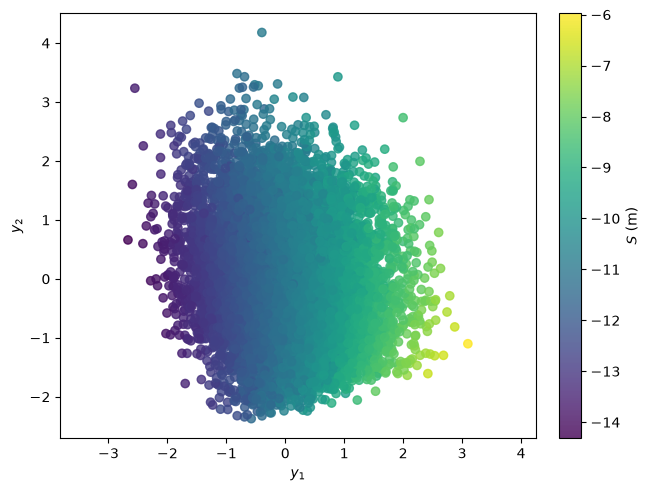

In [10]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=2, qoi_label=r'$S$ (m)')
plt.close(fig)
fig

Against $y_1 = \mathbf w_1^T\mathbf x$ (range $-2.67$ to $3.10$), $S$ lies in a narrow, slightly convex band, with correlation 0.9891. In the $(y_1, y_2)$ plot the colour changes mostly along $y_1$, and the smaller change along $y_2$ (mostly $K_s$) accounts for most of the band's width. No sample floods: the largest overflow among the 10 000 is $-5.97$ m, and the bound on the support is $-3.663$ m, so under Table 4 the dyke is never overtopped.

#### Surrogates on the active variables

We fit polynomials in the active variables and report the leave-one-out $R^2$: a line and a cubic in $y_1$, and a quadratic in $(y_1, y_2)$.

LOO R^2: line in y1 0.9783; cubic in y1 0.9791; quadratic in (y1, y2) 0.99096


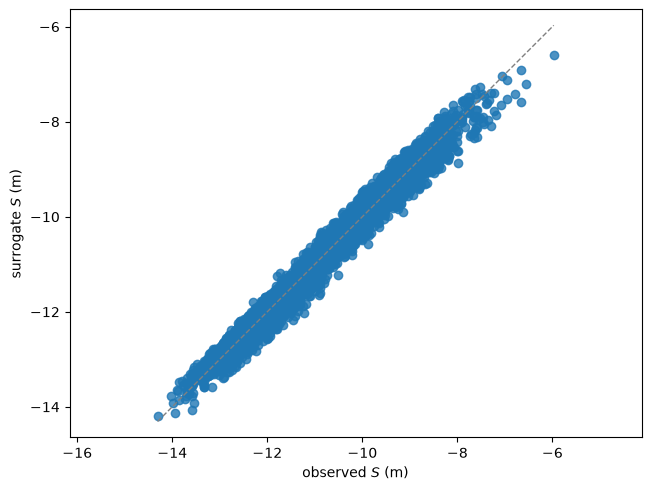

In [11]:
sub2 = ac.with_dimension(sub, 2)
sur1 = ac.fit_surrogate(X=X, f=f, subspace=sub, kind='poly', degree=1)
sur3 = ac.fit_surrogate(X=X, f=f, subspace=sub, kind='poly', degree=3)
sur22 = ac.fit_surrogate(X=X, f=f, subspace=sub2, kind='poly', degree=2)
print(f'LOO R^2: line in y1 {sur1.loo_r_squared:.4f}; cubic in y1 {sur3.loo_r_squared:.4f}; '
      f'quadratic in (y1, y2) {sur22.loo_r_squared:.5f}')
fig, ax = ac.plotting.plot_surrogate_fit(sur3, X=X, f=f, qoi_label=r'$S$ (m)')
plt.close(fig)
fig

A line in $y_1$ has leave-one-out $R^2 = 0.9783$ and a cubic 0.9791, so what the line misses is not curvature along $y_1$ but variation along $y_2$: a quadratic in $(y_1, y_2)$ reaches 0.99096. This is in line with the eigenvalues, where $\lambda_1$ holds 97.0 % of the trace and $\lambda_1 + \lambda_2$ 99.05 %.

#### The same analysis in transformed variables

The affine normalization above leaves the inputs' distributions as they are. The alternative is to transform each non-uniform input to a standard normal, $z_j = \Phi^{-1}(F_j(x_j))$ with $F_j$ its CDF, so that the input space is exact: `ac.Gaussian.reference` blocks for the seven transformed inputs and `ac.Uniform(7, 9)` for $H_d$. The gradient is $\partial S/\partial z_j = \partial S/\partial x_j \cdot dx_j/dz_j$ with $dx_j/dz_j = \varphi(z_j)/\rho_j(x_j)$ (`flood_model.dx_dz`). The transform is monotone in each input, so the signs and the ranking of the weights are comparable with the first analysis, but the active variable is now a nonlinear function of the physical inputs. (A transform to uniforms, $u_j = F_j(x_j)$, would not do: for a triangular input $dx/du \propto u^{-1/2}$ near the ends, and $\mathbb E[(\partial S/\partial u_j)^2]$ is infinite.)

eigenvalues: [1.8327e+00 3.2887e-02 1.0684e-02 4.6932e-03 9.8588e-04 2.3344e-04
 4.1475e-06 1.3426e-08]
n = 1; lambda_1/lambda_2 = 55.7, lambda_2/lambda_3 = 3.08
w1 (transformed): Q +0.4749, Ks -0.2972, Zv +0.3479, Zm -0.0479, Hd -0.7351, Cb -0.1496, L +0.0005, B -0.0079
|w1(transformed) . w1(affine)| = 0.9996
LOO R^2, cubic in the transformed y1: 0.9816


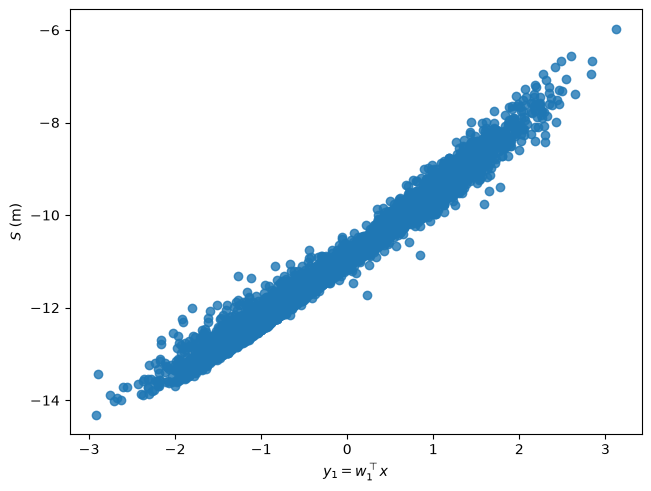

In [12]:
nonu = [0, 1, 2, 3, 5, 6, 7]
Xt, Gt = X.copy(), G.copy()
Xt[:, nonu] = fm.to_gaussian(X)[:, nonu]
Gt[:, nonu] = G[:, nonu] * fm.dx_dz(X)[:, nonu]
space_t = ac.Product([ac.Gaussian.reference(4, names=[f'z_{n}' for n in names[:4]]),
                      ac.Uniform([fm.HD_LO], [fm.HD_HI], names=['Hd']),
                      ac.Gaussian.reference(3, names=[f'z_{n}' for n in names[5:]])])
sub_t = ac.active_subspace(space=space_t, X=Xt, f=f, grads=Gt, estimator='as', nboot=500, rng=SEED)
sub_t = ac.orient(sub_t, by='mean_gradient', grads=Gt)
lt = sub_t.eigenvalues
print('eigenvalues:', np.array2string(lt, precision=4))
print(f'n = {sub_t.n}; lambda_1/lambda_2 = {lt[0] / lt[1]:.1f}, lambda_2/lambda_3 = {lt[1] / lt[2]:.2f}')
wt = sub_t.eigenvectors[:, 0]
print('w1 (transformed):', ', '.join(f'{n} {v:+.4f}' for n, v in zip(names, wt)))
print(f'|w1(transformed) . w1(affine)| = {abs(wt @ w1):.4f}')
sur_t = ac.fit_surrogate(X=Xt, f=f, subspace=sub_t, kind='poly', degree=3)
print(f'LOO R^2, cubic in the transformed y1: {sur_t.loo_r_squared:.4f}')
fig, ax = ac.plotting.plot_sufficient_summary(sub_t, X=Xt, f=f, dims=1, qoi_label=r'$S$ (m)')
plt.close(fig)
fig

In the transformed variables the active subspace is again one-dimensional, with $\lambda_1/\lambda_2 = 55.7$ ($\lambda_2/\lambda_3 = 3.08$), and the first eigenvector is nearly the same, $|\mathbf w_1^{\mathrm{trans}}\cdot\mathbf w_1| = 0.9996$: $H_d$ $-0.735$, $Q$ $+0.475$, $Z_v$ $+0.348$, $K_s$ $-0.297$, $C_b$ $-0.150$. A cubic in the transformed $y_1$ has leave-one-out $R^2 = 0.9816$. So the result does not depend on how the non-uniform inputs are normalized ($H_d$ has the same scale in both analyses).

#### The cost output

For completeness, the same estimate for $C_p$ (Eq. (4.21)) in the space of the first analysis. Its gradient is $\partial C_p/\partial S\cdot\nabla S$ plus $1/20$ in the $H_d$ component when $H_d > 8$ m; at the kink we use the derivative from the left (no sample lies exactly on it).

eigenvalues: [1.219e-03 5.944e-04 3.864e-05 5.691e-06 1.254e-07 2.234e-10 2.031e-14
 4.032e-37]
n = 1; lambda_1/lambda_2 = 2.05, lambda_2/lambda_3 = 15.38
w1(Cp): Q +0.3058, Ks -0.3486, Zv +0.2329, Zm -0.0457, Hd -0.8484, Cb -0.0936, L +0.0004, B -0.0070
Cp in [0.6243, 1.0356] million euros; samples with Hd > 8: 0.492


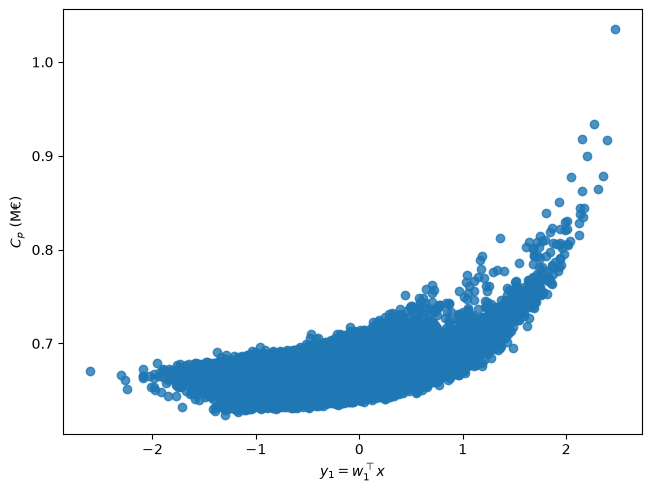

In [13]:
sub_c = ac.active_subspace(space=space, X=X, f=cp, grads=Gcp, estimator='as', nboot=500, rng=SEED)
sub_c = ac.orient(sub_c, by='mean_gradient', grads=Gcp)
lc = sub_c.eigenvalues
wc = sub_c.eigenvectors[:, 0]
print('eigenvalues:', np.array2string(lc, precision=3))
print(f'n = {sub_c.n}; lambda_1/lambda_2 = {lc[0] / lc[1]:.2f}, lambda_2/lambda_3 = {lc[1] / lc[2]:.2f}')
print('w1(Cp):', ', '.join(f'{n} {v:+.4f}' for n, v in zip(names, wc)))
print(f'Cp in [{cp.min():.4f}, {cp.max():.4f}] million euros; samples with Hd > 8: {(X[:, 4] > 8).mean():.3f}')
fig, ax = ac.plotting.plot_sufficient_summary(sub_c, X=X, f=cp, dims=1, qoi_label=r'$C_p$ (M€)')
plt.close(fig)
fig

The library's gap rule, which compares differences of eigenvalues, picks $n = 1$ for $C_p$, but the ratios, $\lambda_1/\lambda_2 = 2.05$ and $\lambda_2/\lambda_3 = 15.38$, point to a two-dimensional active subspace. Its first eigenvector ($H_d$ $-0.848$, $K_s$ $-0.349$, $Q$ $+0.306$, $Z_v$ $+0.233$) gives more weight to $H_d$ than $\mathbf w_1$ of $S$ does, because $H_d$ also enters the investment term, whose slope jumps from 0 to $1/20$ at the kink $H_d = 8$ m (49.2 % of the samples lie above it). The summary plot is convex: the maintenance cost rises steeply as $S$ approaches 0 from below. $C_p$ ranges from 0.6243 to 1.0356 million euros, and the flooding term $\mathbb 1_{S>0}$ is zero at every sample.

### Comparison with the paper

The paper reports Sobol' indices and DGSM, not an active subspace (Table 5, p. 15, for $S$; Table 6, p. 16, for $C_p$). We compare them with exact values from quadrature (`flood_model.exact_moments`), with sample estimates from the 10 000 gradients, and with the activity scores $\alpha_j = \lambda_1 w_{1j}^2$ of the one-dimensional active subspace. Three normalizations of the DGSM appear: the raw $\nu_j$ (in the units of the inputs, which is why the paper finds $Q$ unimportant by $\nu_j$ alone, p. 16); $\sigma_j^2\nu_j/D$, the DGSM of the standardized input divided by $D = \mathrm{Var}(S)$; and the paper's bound $\Upsilon_j = C_j\nu_j/D$ (Eq. (4.18)), with $C_j$ the Poincaré-type constant of the marginal: $(b-a)^2/\pi^2$ for the uniform (Sobol' and Kucherenko [[3]](https://doi.org/10.1016/j.matcom.2009.01.023)) and $1/\rho_j(m_j)^2$ (Cheeger constant at the median, Theorem 3.2) for the log-concave marginals. The paper does not list its $C_j$ for this model, so the cell also prints the constants implied by its Table 5.

In [14]:
nu_hat = np.mean(G**2, axis=0)
C_j, C_ks_normal = fm.poincare_constants()
D = ex['var']
paper = dict(S=[0.343, 0.130, 0.185, 0.003, 0.276, 0.036, 0.000, 0.000],
             ST=[0.353, 0.139, 0.186, 0.003, 0.276, 0.036, 0.000, 0.000],
             nu=[1.296e-06, 3.286e-03, 1.123e+00, 2.279e-02, 8.389e-01, 8.389e-01, 2.147e-08, 2.386e-05],
             tau=[1.072, 1.033, 1377.41, 33.742, 23.77, 1268.90, 0.268, 1.070],
             U=[2.807, 0.198, 0.561, 0.011, 0.340, 0.105, 0.000, 0.000])
paper = {k: np.array(v) for k, v in paper.items()}
alpha = ac.activity_scores(sub, n=1)
print(f"{'':4s} {'S_j':>13s} {'ST_j':>13s} {'nu_j paper':>11s} {'nu_j exact':>11s} {'nu_j sample':>11s} "
      f"{'paper/exact':>11s} {'s^2 nu/D':>9s} {'alpha_j/D':>9s} {'Ups paper':>9s} {'Ups exact':>9s}")
for j, n in enumerate(names):
    print(f'{n:4s} {paper["S"][j]:.3f}/{ex["S"][j]:.4f} {paper["ST"][j]:.3f}/{ex["ST"][j]:.4f} '
          f'{paper["nu"][j]:11.4e} {ex["nu"][j]:11.4e} {nu_hat[j]:11.4e} {paper["nu"][j] / ex["nu"][j]:11.4f} '
          f'{sd[j]**2 * ex["nu"][j] / D:9.4f} {alpha[j] / D:9.4f} {paper["U"][j]:9.3f} '
          f'{C_j[j] * ex["nu"][j] / D:9.4f}')
print(f'\nD = Var(S): exact {D:.4f} m^2; implied by Table 5 through S_Hd = Var(Hd)/D: {(1 / 3) / 0.276:.3f}')
print('constants C_j used here:', np.array2string(C_j, precision=4), f'(Ks with the normal-law C = sigma^2: {C_ks_normal:g})')
with np.errstate(divide='ignore', invalid='ignore'):
    print('C_j implied by Table 5, Ups_j / nu_j (i.e. with D = 1):',
          np.array2string(paper['U'] / paper['nu'], precision=4))
w_tau = (1 - 3 * X + 3 * X**2) / 6                 # Sobol-Kucherenko weight for U[0,1], applied to physical x
tau_hat = np.mean(G**2 * w_tau, axis=0)
print('tau_j: paper / (sample E[(dS/dx_j)^2 w(x_j)] with w applied to physical x):',
      np.array2string(paper['tau'] / tau_hat, precision=3))
rank = lambda v: [names[i] for i in np.argsort(-np.asarray(v))[:4]]
print(f'top four: paper ST {rank(paper["ST"])}, exact ST {rank(ex["ST"])}, |w1| {rank(np.abs(w1))}, '
      f'paper Upsilon {rank(paper["U"])}, exact Upsilon {rank(C_j * ex["nu"] / D)}, paper nu {rank(paper["nu"])}')
nu_cp = np.mean(Gcp**2, axis=0)
paper_nu_cp = np.array([1.3906e-06, 8.5307e-03, 1.3891e+00, 4.6038e-02, 1.5366e+00, 9.4628e-01, 4.0276e-08, 4.4788e-05])
print('Cp: Table 6 nu_j / sample nu_j:', np.array2string(paper_nu_cp / nu_cp, precision=0))

               S_j          ST_j  nu_j paper  nu_j exact nu_j sample paper/exact  s^2 nu/D alpha_j/D Ups paper Ups exact
Q    0.343/0.3448 0.353/0.3536  1.2960e-06  1.5447e-06  1.5412e-06      0.8390    0.4141    0.4010     2.807    2.8482
Ks   0.130/0.1338 0.139/0.1423  3.2860e-03  3.9210e-03  3.9788e-03      0.8381    0.1842    0.1560     0.198    1.2639
Zv   0.185/0.1896 0.186/0.1899  1.1230e+00  1.3394e+00  1.3407e+00      0.8385    0.1901    0.1891     0.561    1.1404
Zm   0.003/0.0035 0.003/0.0038  2.2790e-02  2.7156e-02  2.7370e-02      0.8392    0.0039    0.0035     0.011    0.0231
Hd   0.276/0.2838 0.276/0.2838  8.3890e-01  1.0000e+00  1.0000e+00      0.8389    0.2838    0.8455     0.340    0.3451
Cb   0.036/0.0355 0.036/0.0355  8.3890e-01  1.0000e+00  1.0000e+00      0.8389    0.0355    0.0352     0.105    0.2129
L    0.000/0.0000 0.000/0.0000  2.1470e-08  2.5601e-08  2.5870e-08      0.8386    0.0000    0.0000     0.000    0.0000
B    0.000/0.0001 0.000/0.0001  2.3860e-05  2.

| Quantity | Paper value | Notebook value |
|---|---|---|
| $D = \mathrm{Var}(S)$ (m$^2$) | not reported ($S_{H_d} = 0.276$ implies 1.208) | 1.1745 exact; 1.2087 sample |
| $S_j$ / $ST_j$ for $Q$ | 0.343 / 0.353 [Table 5] | 0.3448 / 0.3536 exact |
| $S_j$ / $ST_j$ for $K_s$ | 0.130 / 0.139 | 0.1338 / 0.1423 |
| $S_j$ / $ST_j$ for $Z_v$ | 0.185 / 0.186 | 0.1896 / 0.1899 |
| $S_j$ / $ST_j$ for $Z_m$ | 0.003 / 0.003 | 0.0035 / 0.0038 |
| $S_j$ / $ST_j$ for $H_d$ | 0.276 / 0.276 | 0.2838 / 0.2838 |
| $S_j$ / $ST_j$ for $C_b$ | 0.036 / 0.036 | 0.0355 / 0.0355 |
| $S_j$ / $ST_j$ for $L$, $B$ | 0.000 / 0.000 | 0.0000 / 0.0000; 0.0001 / 0.0001 |
| $\nu_{H_d}$, $\nu_{C_b}$ | 0.8389, 0.8389 [Table 5] | 1, 1 (exact: $\partial S/\partial H_d = \partial S/\partial C_b = -1$) |
| $\nu_Q$, $\nu_{K_s}$ | $1.296\times10^{-6}$, $3.286\times10^{-3}$ | $1.5447\times10^{-6}$, $3.9210\times10^{-3}$ exact ($1.5412\times10^{-6}$, $3.9788\times10^{-3}$ sample) |
| $\nu_{Z_v}$, $\nu_{Z_m}$ | 1.123, $2.279\times10^{-2}$ | 1.3394, $2.7156\times10^{-2}$ exact (1.3407, $2.7370\times10^{-2}$ sample) |
| $\nu_L$, $\nu_B$ | $2.147\times10^{-8}$, $2.386\times10^{-5}$ | $2.5601\times10^{-8}$, $2.8453\times10^{-5}$ exact |
| paper $\nu_j$ / exact $\nu_j$ | — | 0.8381–0.8392 for all eight inputs |
| $\tau_j$ (weighted DGSM) | Table 5 | paper / our reconstruction 0.829–0.840 (see below) |
| $\Upsilon_j$ for $Q, K_s, Z_v, Z_m, H_d, C_b$ | 2.807, 0.198, 0.561, 0.011, 0.340, 0.105 | 2.8482, 1.2639, 1.1404, 0.0231, 0.3451, 0.2129 (exact $\nu_j$ and $D$, our $C_j$) |
| Four most important inputs | $Q, H_d, K_s, Z_v$ (text, p. 15); by $ST_j$: $Q, H_d, Z_v, K_s$ | by exact $ST_j$: $Q, H_d, Z_v, K_s$; by $\lvert w_{1j}\rvert$: $H_d, Q, Z_v, K_s$ |
| Active subspace | not reported | $n = 1$, $\lambda_1/\lambda_2 = 47.0$; line in $y_1$: LOO $R^2 = 0.9783$ |
| $\nu_j$ of the cost $C_p$ | Table 6 (e.g. $\nu_{H_d} = 1.5366$) | 1391–1475 times smaller (sample); not reconciled |

**Sobol' indices.** The exact values agree with Table 5 to within 0.008 (largest difference: $S_{H_d}$, 0.276 against 0.2838), which is consistent with the Monte Carlo error of the paper's estimator (it reports no standard deviations for this model).

**DGSM.** All eight $\nu_j$ of Table 5 are 0.838–0.839 times the exact values, including $\nu_{H_d} = \nu_{C_b} = 0.8389$, where the exact value is 1 because $\partial S/\partial H_d = \partial S/\partial C_b = -1$ at every point. One factor common to every input points to a normalization slip in the paper's estimator (for instance a sum over fewer than $10^4$ valid points divided by $10^4$), not to the model; we cannot tell its cause from the paper. The weighted measures $\tau_j$ carry the same factor: Table 5 is reproduced (ratio 0.829–0.840) by applying the weight $w(x) = (1 - 3x + 3x^2)/6$ of the paper's Remark 2.1 (after Sobol' and Kucherenko), which is meant for inputs on $[0, 1]$, to the unnormalized inputs; that alone makes $\tau_j$ large for $Z_v$ and $C_b$, whose values are 49–56 m.

**The bound $\Upsilon_j$.** For $Q$ and $H_d$, whose constants are unambiguous, Table 5's $\Upsilon_j$ equal $C_j\nu_j$ with Table 5's $\nu_j$ and no division by $D$ (equivalently $D = 1$; the exact value is 1.1745). Read this way, the implied constants are $C_Q = 2.1659\times10^6$, matching the Cheeger constant of the truncated Gumbel at its median ($2.1656\times10^6$ here), and $C_{H_d} = 0.40529 = 4/\pi^2$; for the triangular inputs they are about half of $1/\rho_j(m_j)^2$ (0.4996, 0.4827 and 0.1252 against 1, 1 and 0.25), and for $K_s$ 60.3, which is neither $\sigma^2 = 64$ nor the Cheeger value 378.6. With exact $\nu_j$, exact $D$ and our constants, $\Upsilon_j \ge ST_j$ still holds for every input, but the ranking by $\Upsilon_j$ becomes $Q, K_s, Z_v, H_d$.

**Active subspace and DGSM.** The column `s^2 nu/D` is the DGSM of the standardized input, $\sigma_j^2\nu_j/D$, a renormalization of the kind the paper says the raw $\nu_j$ lack (p. 16). For $H_d$ and $C_b$, which enter $S$ linearly, it equals $ST_j$ exactly; it exceeds $ST_j$ by 17 % for $Q$ and 29 % for $K_s$, where $H$ is curved. The activity scores [[4]](https://doi.org/10.1016/j.ress.2017.01.013) $\alpha_j = \lambda_1 w_{1j}^2$ divided by $D$ are close to it (0.4010 against 0.4141 for $Q$, 0.1891 against 0.1901 for $Z_v$), except for $H_d$, whose 0.8455 is about three times 0.2838 because the library's `Uniform` scales $H_d$ by its half-range, $\sqrt3$ standard deviations. So the one-dimensional active subspace, from 10 000 gradients, picks out the same four inputs as the Sobol' indices, which the paper computed from $2\times10^7$ runs.

### References

[1] M. Lamboni, B. Iooss, A.-L. Popelin, and F. Gamboa. [Derivative-based global sensitivity measures: General links with Sobol' indices and numerical tests](https://doi.org/10.1016/j.matcom.2013.02.002). *Mathematics and Computers in Simulation*, 87:45–54, 2013. (Manuscript read: arXiv:1202.0943v2.)

[2] B. Iooss. Revue sur l'analyse de sensibilité globale de modèles numériques. *Journal de la Société Française de Statistique*, 152(1):1–23, 2011.

[3] I. M. Sobol' and S. Kucherenko. [Derivative based global sensitivity measures and their link with global sensitivity indices](https://doi.org/10.1016/j.matcom.2009.01.023). *Mathematics and Computers in Simulation*, 79(10):3009–3017, 2009.

[4] P. G. Constantine and P. Diaz. [Global sensitivity metrics from active subspaces](https://doi.org/10.1016/j.ress.2017.01.013). *Reliability Engineering & System Safety*, 162:1–13, 2017.

[5] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[R1]: https://doi.org/10.1016/j.matcom.2013.02.002
[R3]: https://doi.org/10.1016/j.matcom.2009.01.023
[R4]: https://doi.org/10.1016/j.ress.2017.01.013

### Acknowledgments

From [[1]][R1], Sec. 6: "Part of this work has been backed by French National Research Agency (ANR) through COSINUS program (project COSTA BRAVA noANR-09-COSI-015)."

In [15]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 7.7 s
